# E–I Wilson–Cowan neural field: bifurcation and stimulus-dependent patterns

This notebook specializes the finite-wavenumber Hopf calculation in `notes/notes.tex` and `notes/computations.tex` to the numerical Wilson–Cowan model in `wc2dn.txt`. It provides:

1. the E–I neural-field model and the `wc2dn.txt` parameter set;
2. a linear Fourier-mode estimate of the first bifurcation;
3. direct simulations below and above onset; and
4. space–time plots with **space on the x-axis** and **time on the y-axis**, showing stimulus, excitatory output, and the projected critical amplitudes $|A(t)|,|B(t)|$ in adjacent columns.

The TeX analysis uses one spatial coordinate. Accordingly, this notebook uses the one-dimensional, y-invariant subspace of the 2D torus model. Because the Gaussian kernel in `wc2dn.txt` is separable, its Fourier multiplier for a 2D mode `(m, 0)` is exactly the multiplier used below.

## 1. Model

The equations implemented here are the equations in `wc2dn.txt`, restricted to one spatial coordinate:

$$
\tau_E\partial_t E=-E+a_{EE}(K_E*f_E(E))-a_{IE}(K_I*f_I(I))+S_E(x,t),
$$
$$
\tau_I\partial_t I=-I+a_{EI}(K_E*f_E(E))-a_{II}(K_I*f_I(I))+S_I(x,t).
$$

Here $f_p(u)=\sigma(u-\theta_p)-\sigma(-\theta_p)$, $\sigma(z)=(1+e^{-4z})^{-1}$, and $K_p(x)\propto e^{-(x/\sigma_p)^2}$ is normalized to unit mass on the periodic grid. As in the source file, $S_I=r_{IE}S_E$. The bifurcation parameter is $a_{EE}$.

The source code applies each sigmoid to its population field *before* convolution. The linearization below follows that implementation exactly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "image.cmap": "RdBu_r",
})

# Parameters copied from wc2dn.txt. aee is varied below.
BASE = dict(
    N=60,
    aie=10.0, aei=10.0, aii=8.0,
    sige=4.0, sigi=8.0,
    te=0.5, ti=0.3,
    taue=3.0, taui=6.6,
    rie=0.0,
    dt=0.1, total=500.0, save_every=5,
)

for key, value in BASE.items():
    print(f"{key:>10s} = {value}")

         N = 60
       aie = 10.0
       aei = 10.0
       aii = 8.0
      sige = 4.0
      sigi = 8.0
        te = 0.5
        ti = 0.3
      taue = 3.0
      taui = 6.6
       rie = 0.0
        dt = 0.1
     total = 500.0
save_every = 5


In [2]:
def sigmoid(u):
    # Clipping only prevents overflow; it does not affect the relevant range.
    return 1.0 / (1.0 + np.exp(-4.0 * np.clip(u, -50.0, 50.0)))

def f_thresh(u, theta):
    return sigmoid(u - theta) - sigmoid(-theta)

def sigmoid_slope_at_origin(theta):
    # d/du [sigmoid(u-theta)-sigmoid(-theta)] at u=0
    z = np.exp(4.0 * theta)
    return 4.0 * z / (1.0 + z) ** 2

def gaussian_kernel_1d(N, sigma):
    idx = np.arange(N)
    dx = idx - N * np.round(idx / N).astype(int)
    kernel = np.exp(-(dx / sigma) ** 2)
    return kernel / kernel.sum()

def kernel_transforms(params=BASE):
    ke = gaussian_kernel_1d(params["N"], params["sige"])
    ki = gaussian_kernel_1d(params["N"], params["sigi"])
    return np.fft.fft(ke), np.fft.fft(ki)

KE_FFT, KI_FFT = kernel_transforms()
print("f'_E(0) =", sigmoid_slope_at_origin(BASE["te"]))
print("f'_I(0) =", sigmoid_slope_at_origin(BASE["ti"]))

f'_E(0) = 0.4199743416140261
f'_I(0) = 0.7115777625872228


## 2. Linear bifurcation estimate

For spatial Fourier mode $m$, let $\widehat K_E(m)$ and $\widehat K_I(m)$ be the discrete FFT multipliers. Linearization about $E=I=0$ gives

$$
M_m(a_{EE})=
\begin{pmatrix}
(-1+a_{EE}f'_E(0)\widehat K_E(m))/\tau_E & -a_{IE}f'_I(0)\widehat K_I(m)/\tau_E\\
 a_{EI}f'_E(0)\widehat K_E(m)/\tau_I & (-1-a_{II}f'_I(0)\widehat K_I(m))/\tau_I
\end{pmatrix}.
$$

The estimated bifurcation is the first value of $a_{EE}$ for which the largest real part over all spatial modes reaches zero. A nonzero imaginary part at the crossing identifies a finite-wavenumber Hopf bifurcation, as assumed by the notes.

In [3]:
def linear_matrix(mode, aee, params=BASE):
    ge = sigmoid_slope_at_origin(params["te"])
    gi = sigmoid_slope_at_origin(params["ti"])
    ke = KE_FFT[mode].real
    ki = KI_FFT[mode].real
    return np.array([
        [(-1.0 + aee * ge * ke) / params["taue"],
         -params["aie"] * gi * ki / params["taue"]],
        [params["aei"] * ge * ke / params["taui"],
         (-1.0 - params["aii"] * gi * ki) / params["taui"]],
    ])

def modal_eigenvalues(mode, aee, params=BASE):
    return np.linalg.eigvals(linear_matrix(mode, aee, params))

def leading_mode(aee, params=BASE):
    candidates = []
    for mode in range(params["N"] // 2 + 1):
        eig = modal_eigenvalues(mode, aee, params)
        j = np.argmax(eig.real)
        candidates.append((eig[j].real, mode, eig[j]))
    return max(candidates, key=lambda row: row[0])

def estimate_bifurcation(aee_lo=4.0, aee_hi=9.0, tol=1e-12):
    if leading_mode(aee_lo)[0] >= 0 or leading_mode(aee_hi)[0] <= 0:
        raise ValueError("The supplied interval must bracket the first crossing.")
    lo, hi = aee_lo, aee_hi
    while hi - lo > tol:
        mid = 0.5 * (lo + hi)
        if leading_mode(mid)[0] < 0:
            lo = mid
        else:
            hi = mid
    growth, mode, eig = leading_mode(hi)
    return hi, mode, eig

aee_star, k0, critical_eig = estimate_bifurcation()
omega0 = abs(critical_eig.imag)
period0 = 2.0 * np.pi / omega0

print(f"Estimated aEE*       = {aee_star:.6f}")
print(f"Critical mode k0     = {k0}")
print(f"Critical eigenvalue  = {critical_eig.real:+.3e} {critical_eig.imag:+.6f}i")
print(f"Hopf frequency omega = {omega0:.6f}")
print(f"Hopf period          = {period0:.3f}")

Estimated aEE*       = 7.024921
Critical mode k0     = 3
Critical eigenvalue  = +1.595e-14 +0.318128i
Hopf frequency omega = 0.318128
Hopf period          = 19.751


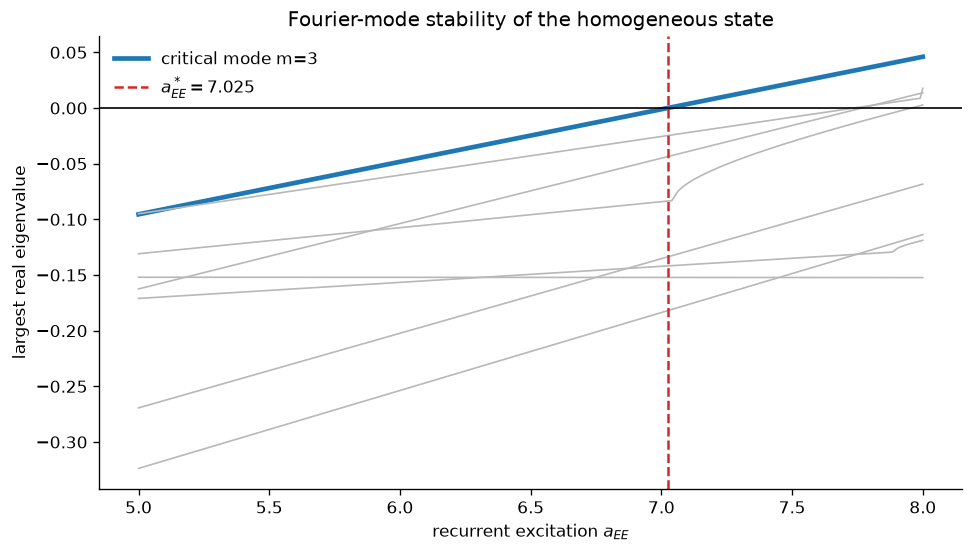

In [4]:
aee_values = np.linspace(5.0, 8.0, 301)
modes_to_show = range(0, 8)

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
for mode in modes_to_show:
    growth = [modal_eigenvalues(mode, aee).real.max() for aee in aee_values]
    if mode == k0:
        ax.plot(aee_values, growth, lw=2.8, label=f"critical mode m={mode}")
    else:
        ax.plot(aee_values, growth, color="0.72", lw=1.0)
ax.axhline(0.0, color="k", lw=1.0)
ax.axvline(aee_star, color="C3", ls="--", lw=1.5, label=fr"$a_{{EE}}^*={aee_star:.3f}$")
ax.set(xlabel=r"recurrent excitation $a_{EE}$",
       ylabel="largest real eigenvalue",
       title="Fourier-mode stability of the homogeneous state")
ax.legend(frameon=False)
plt.show()

### How to read the bifurcation plot

Each curve follows one spatial Fourier mode while recurrent excitation $a_{EE}$ is increased. The vertical coordinate is the largest real part of that mode's two E–I eigenvalues:

- below the horizontal zero line, perturbations in that mode decay;
- above zero, they grow;
- the first curve to touch zero determines the loss of stability.

Here mode $m=3$ crosses first at $a_{EE}^*\approx7.025$. Thus the emerging field has three spatial cycles around the 60-point periodic domain, or wavelength $60/3=20$ grid units. Its eigenvalue has imaginary part $\omega_0\approx0.318$, so it also oscillates in time with period $2\pi/\omega_0\approx19.75$. A nonzero spatial mode plus a nonzero temporal frequency is a finite-wavenumber Hopf (Turing–Hopf) bifurcation. The plot predicts linear onset and the initially selected mode; it does not predict the final nonlinear amplitude or whether the saturated solution is standing or traveling.

The discrete estimate is close to, but not exactly equal to, the comment `aee ~ 7.049` in `wc2dn.txt`: this notebook evaluates the normalized, finite-$N$ kernel FFT actually used by the simulator.

## 3. Nonlinear simulation and forcing

The simulator accepts all of the following additive E-cell inputs:

- `direct_amp`: a traveling critical-mode probe $q_d\cos(kx-\omega t)$;
- `temporal_amp`: the notes' spatially uniform temporal forcing $q_t\cos(\omega_t t)$;
- `spatial_amp`: the notes' time-independent spatial forcing $q_x\cos(k_xx)$;
- an on/off window, useful for distinguishing a driven response below onset from a self-sustained response above onset.

For the weakly nonlinear resonances discussed in the notes, use `temporal_omega = 2*omega0` and `spatial_mode = 2*k0`. The direct probe is not the separated forcing of the notes; it is included as a clean numerical stability test because it seeds exactly one critical traveling-wave harmonic.

In [5]:
def forcing_at_time(t, x, spec, N):
    on = spec.get("on", -np.inf)
    off = spec.get("off", np.inf)
    if not (on <= t < off):
        return np.zeros_like(x, dtype=float)

    stimulus = np.zeros_like(x, dtype=float)
    stimulus += spec.get("direct_amp", 0.0) * np.cos(
        2.0 * np.pi * spec.get("direct_mode", k0) * x / N
        - spec.get("direct_omega", omega0) * t
    )
    stimulus += spec.get("temporal_amp", 0.0) * np.cos(
        spec.get("temporal_omega", 2.0 * omega0) * t
    )
    stimulus += spec.get("spatial_amp", 0.0) * np.cos(
        2.0 * np.pi * spec.get("spatial_mode", 2 * k0) * x / N
    )
    return stimulus

def simulate_wc_1d(aee, stimulus=None, params=BASE, seed=2, initial_scale=0.02):
    stimulus = {} if stimulus is None else dict(stimulus)
    N, dt = params["N"], params["dt"]
    x = np.arange(N, dtype=float)
    rng = np.random.default_rng(seed)
    E = initial_scale * rng.standard_normal(N)
    I = initial_scale * rng.standard_normal(N)

    n_steps = int(round(params["total"] / dt))
    times, E_history, I_history, S_history = [], [], [], []

    for step in range(n_steps):
        t = step * dt
        S_E = forcing_at_time(t, x, stimulus, N)
        S_I = params["rie"] * S_E

        conv_e = np.fft.ifft(KE_FFT * np.fft.fft(f_thresh(E, params["te"]))).real
        conv_i = np.fft.ifft(KI_FFT * np.fft.fft(f_thresh(I, params["ti"]))).real

        dE = (-E + aee * conv_e - params["aie"] * conv_i + S_E) / params["taue"]
        dI = (-I + params["aei"] * conv_e - params["aii"] * conv_i + S_I) / params["taui"]
        E = E + dt * dE
        I = I + dt * dI

        if step % params["save_every"] == 0:
            times.append(t)
            E_history.append(E.copy())
            I_history.append(I.copy())
            S_history.append(S_E.copy())

    return {
        "t": np.asarray(times), "x": x,
        "E": np.asarray(E_history), "I": np.asarray(I_history),
        "stimulus": np.asarray(S_history),
        "aee": aee, "stimulus_spec": stimulus,
    }

def symmetric_limit(array, percentile=99.0):
    limit = np.percentile(np.abs(array), percentile)
    return max(float(limit), 1e-12)

# Critical right eigenvector, normalized so that its E component is one.
_critical_eigenvalues, _critical_eigenvectors = np.linalg.eig(linear_matrix(k0, aee_star))
_positive_hopf = np.argmax(_critical_eigenvalues.imag)
CRITICAL_PHI = _critical_eigenvectors[:, _positive_hopf]
CRITICAL_PHI = CRITICAL_PHI / CRITICAL_PHI[0]
CRITICAL_BASIS = np.column_stack([CRITICAL_PHI, np.conj(CRITICAL_PHI)])

def critical_amplitudes(result):
    """Project the k0 E/I Fourier coefficient onto the Hopf eigenvector pair.

    The returned A and B use the convention in the notes, with the fast
    factors exp(+/- i*omega0*t) removed. Their absolute normalization
    follows the choice CRITICAL_PHI[E] = 1.
    """
    N = result["E"].shape[1]
    e_hat = np.fft.fft(result["E"], axis=1)[:, k0] / N
    i_hat = np.fft.fft(result["I"], axis=1)[:, k0] / N
    modal_coefficients = np.column_stack([e_hat, i_hat])
    fast_amplitudes = np.linalg.solve(CRITICAL_BASIS, modal_coefficients.T).T
    A = fast_amplitudes[:, 0] * np.exp(-1j * omega0 * result["t"])
    B = np.conj(fast_amplitudes[:, 1] * np.exp(1j * omega0 * result["t"]))
    return A, B

def plot_stimulus_and_output(
    results, row_titles=None, output="E", figsize=None,
    time_window=None, contrast_percentile=99.0, shared_column_scales=False,
    column_limits=None,
):
    if isinstance(results, dict):
        results = [results]
    nrows = len(results)
    if row_titles is None:
        row_titles = [fr"$a_{{EE}}={r['aee']:.3f}$" for r in results]
    if figsize is None:
        # A tall row makes motion/phase slopes much easier to see when time is vertical.
        figsize = (18, 4.5 * nrows)

    def time_mask_for(result):
        if time_window is None:
            return np.ones(result["t"].shape, dtype=bool)
        t_min, t_max = time_window
        mask = (result["t"] >= t_min) & (result["t"] <= t_max)
        if not np.any(mask):
            raise ValueError("time_window does not overlap the saved simulation times")
        return mask

    shared_limits = None if column_limits is None else list(column_limits)
    if shared_limits is not None and len(shared_limits) != 3:
        raise ValueError("column_limits must contain stimulus, output, and amplitude limits")
    if shared_limits is None and shared_column_scales:
        stimulus_values, output_values, amplitude_values = [], [], []
        for result in results:
            mask = time_mask_for(result)
            stimulus_values.append(result["stimulus"][mask].ravel())
            output_values.append(result[output][mask].ravel())
            A, B = critical_amplitudes(result)
            amplitude_values.extend([np.abs(A[mask]), np.abs(B[mask])])
        shared_limits = [
            symmetric_limit(np.concatenate(stimulus_values), percentile=contrast_percentile),
            symmetric_limit(np.concatenate(output_values), percentile=contrast_percentile),
            max(float(np.percentile(np.concatenate(amplitude_values), contrast_percentile)), 1e-12),
        ]

    fig, axes = plt.subplots(nrows, 3, figsize=figsize, squeeze=False, constrained_layout=True)
    for row, (result, title) in enumerate(zip(results, row_titles)):
        time_mask = time_mask_for(result)
        shown_t = result["t"][time_mask]
        extent = [result["x"][0], result["x"][-1], shown_t[0], shown_t[-1]]
        for col, (field, name) in enumerate([
            (result["stimulus"], r"stimulus $S_E(x,t)$"),
            (result[output], fr"{output}-cell output"),
        ]):
            shown_field = field[time_mask]
            vmax = (shared_limits[col] if shared_limits is not None else
                    symmetric_limit(shown_field, percentile=contrast_percentile))
            image = axes[row, col].imshow(
                shown_field, origin="lower", aspect="auto", extent=extent,
                vmin=-vmax, vmax=vmax, cmap="RdBu_r", interpolation="nearest"
            )
            axes[row, col].set_title(f"{title}: {name}")
            axes[row, col].set_xlabel("space x (grid units)")
            axes[row, col].set_ylabel("time")
            fig.colorbar(image, ax=axes[row, col], shrink=0.85)

        A, B = critical_amplitudes(result)
        amp_limit = (shared_limits[2] if shared_limits is not None else
                     max(float(np.percentile(
                         np.concatenate([np.abs(A[time_mask]), np.abs(B[time_mask])]),
                         contrast_percentile)), 1e-12))
        shown_A, shown_B = np.abs(A[time_mask]), np.abs(B[time_mask])
        spec = result.get("stimulus_spec", {})
        stim_on = spec.get("on", None)
        stim_off = spec.get("off", None)
        has_finite_window = (stim_on is not None and stim_off is not None and
                             np.isfinite(stim_on) and np.isfinite(stim_off))

        for values, color in [(shown_A, "C0"), (shown_B, "C1")]:
            if has_finite_window:
                before = shown_t < stim_on
                during = (shown_t >= stim_on) & (shown_t < stim_off)
                after = shown_t >= stim_off
                # Before stimulation is dashed; forced and post-forcing dynamics are solid.
                axes[row, 2].plot(values[before], shown_t[before], color=color,
                                  ls="--", lw=1.4)
                axes[row, 2].plot(values[during], shown_t[during], color=color,
                                  ls="-", lw=1.6)
                axes[row, 2].plot(values[after], shown_t[after], color=color,
                                  ls="-", lw=1.4)
            else:
                axes[row, 2].plot(values, shown_t, color=color, ls="-", lw=1.4)

        # Compact legend: colors identify A/B and line style identifies the epoch.
        axes[row, 2].plot([], [], color="C0", lw=1.6, label=r"$|A(t)|$")
        axes[row, 2].plot([], [], color="C1", lw=1.6, label=r"$|B(t)|$")
        if has_finite_window:
            axes[row, 2].plot([], [], color="0.25", ls="--", lw=1.4,
                              label="before stimulus")
            axes[row, 2].plot([], [], color="0.25", ls="-", lw=1.4,
                              label="during / after")
            axes[row, 2].axhline(stim_on, color="0.45", ls=":", lw=1.0)
            axes[row, 2].axhline(stim_off, color="0.45", ls=":", lw=1.0)
        axes[row, 2].set_xlim(0.0, 1.05 * amp_limit)
        axes[row, 2].set_ylim(shown_t[0], shown_t[-1])
        axes[row, 2].set_title(f"{title}: critical amplitudes")
        axes[row, 2].set_xlabel("projected amplitude")
        axes[row, 2].set_ylabel("time")
        axes[row, 2].legend(frameon=False, loc="best")
    plt.show()
    return fig

### 3a. Below and above bifurcation without any stimulus

Both rows have identically zero stimulus and start from the same random perturbation scale. Below onset, the $k_0$ component decays. Above onset, it grows spontaneously. The third column shows the projected magnitudes $|A(t)|$ and $|B(t)|$ of the two counter-propagating critical waves from the TeX notes.

The projection uses the full E/I Fourier coefficient at $k_0$, decomposes it in the Hopf eigenvector basis $(\Phi,\overline\Phi)$, and removes the fast factors $e^{\pm i\omega_0t}$. We normalize $\Phi_E=1$, so amplitude values depend on this stated normalization but their growth, decay, and relative sizes are meaningful.

Below: aEE=6.924921, decay rate=0.004716, decay time=212.0
Above: aEE=7.100000, growth rate=0.003541, growth time=282.4


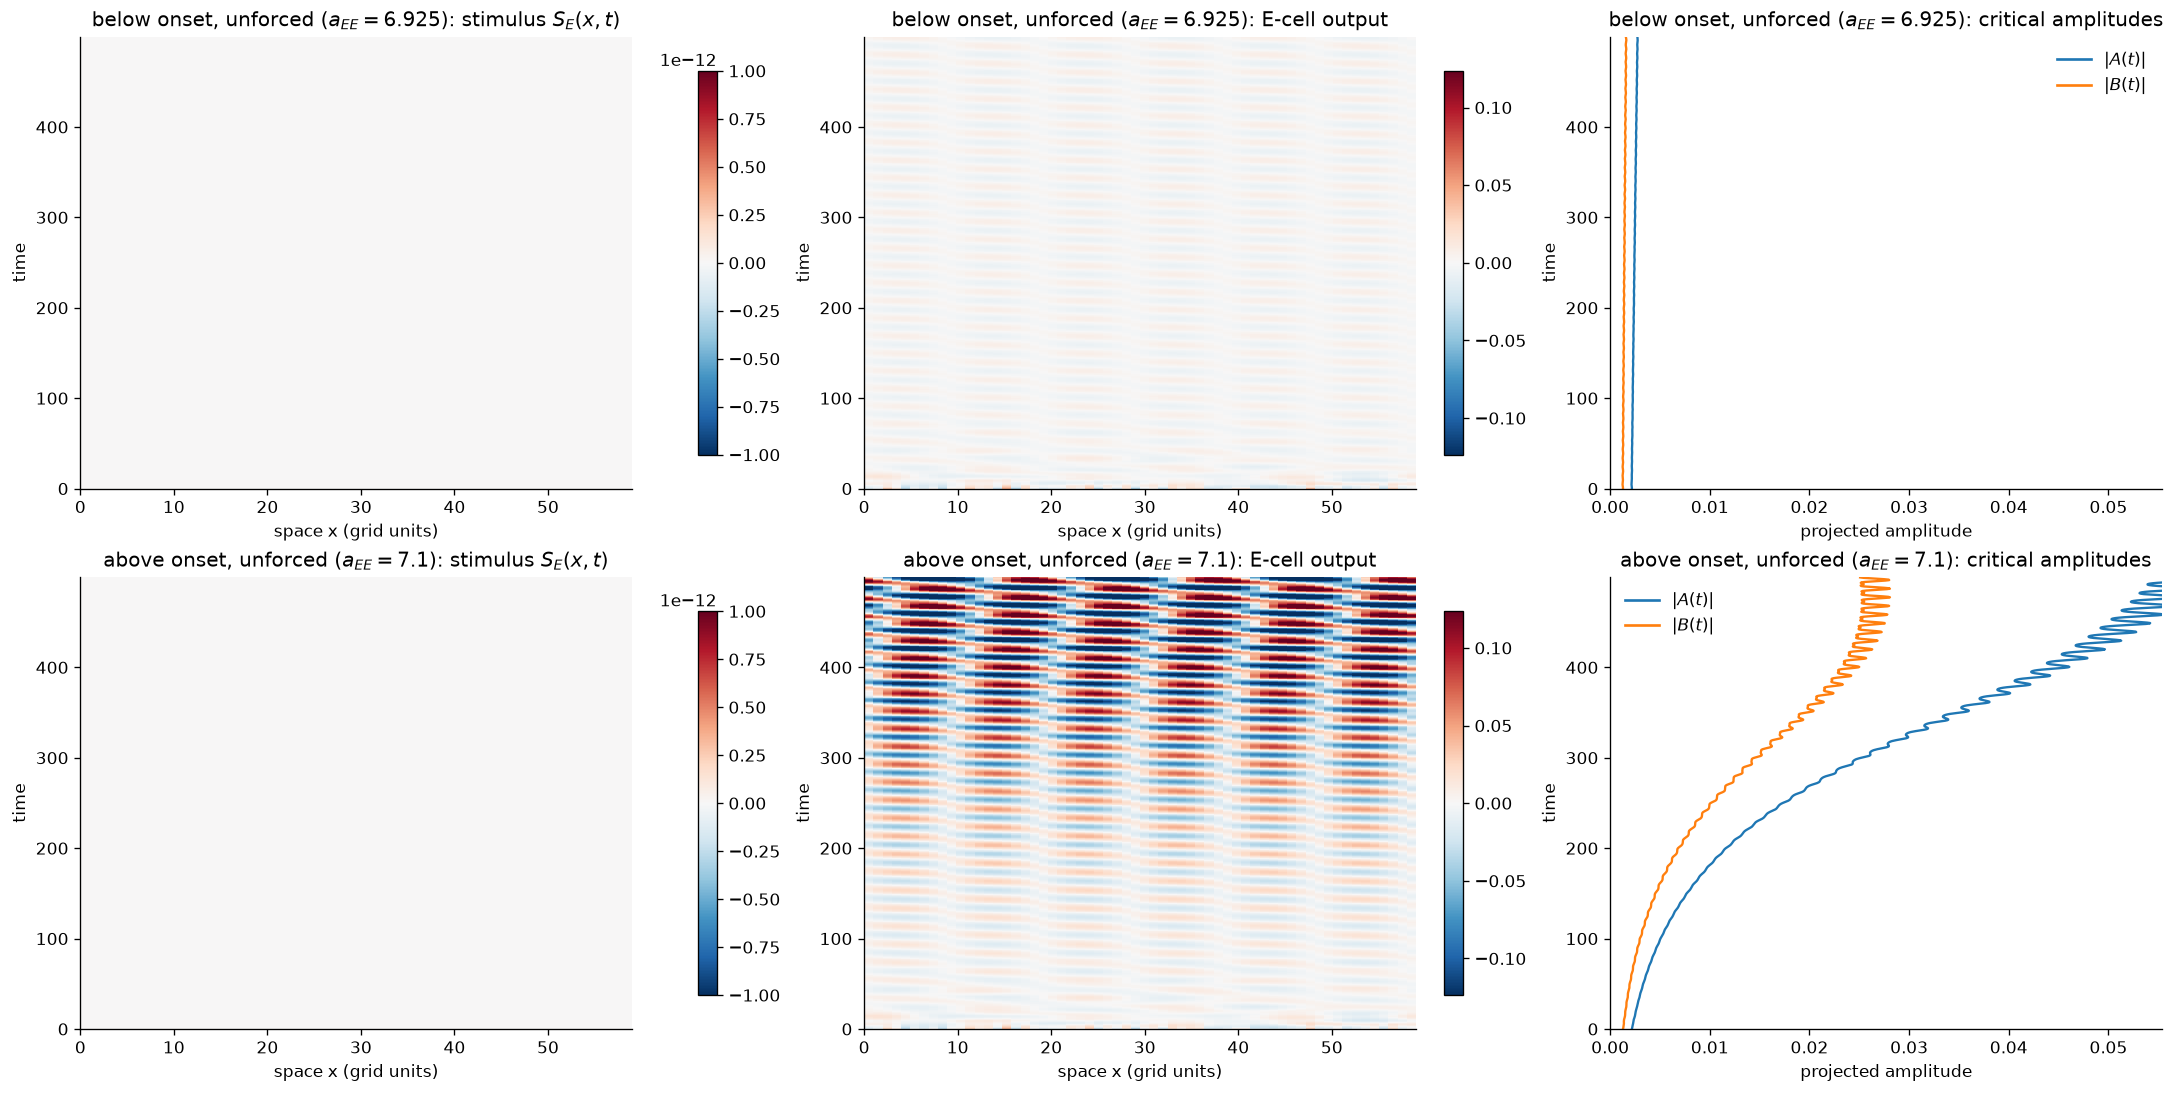

In [6]:
aee_below = aee_star - 0.10
aee_above = 7.1
decay_below = -leading_mode(aee_below)[0]
growth_above = leading_mode(aee_above)[0]
print(f"Below: aEE={aee_below:.6f}, decay rate={decay_below:.6f}, "
      f"decay time={1.0 / decay_below:.1f}")
print(f"Above: aEE={aee_above:.6f}, growth rate={growth_above:.6f}, "
      f"growth time={1.0 / growth_above:.1f}")
below = simulate_wc_1d(aee_below, stimulus={}, seed=4, initial_scale=0.02)
above = simulate_wc_1d(aee_above, stimulus={}, seed=4, initial_scale=0.02)

_ = plot_stimulus_and_output(
    [below, above],
    [fr"below onset, unforced ($a_{{EE}}={aee_below:.3f}$)",
     fr"above onset, unforced ($a_{{EE}}={aee_above}$)"],
    figsize=(18, 9), time_window=(0.0, BASE["total"]),
    contrast_percentile=98.0, shared_column_scales=True,
)

In [7]:
def post_stimulus_summary(result, start=320.0):
    mask = result["t"] >= start
    E = result["E"][mask]
    centered = E - E.mean(axis=1, keepdims=True)
    power = np.mean(np.abs(np.fft.rfft(centered, axis=1)) ** 2, axis=0)
    dominant_mode = 1 + np.argmax(power[1:])
    return E.std(), dominant_mode

for label, result in [("below", below), ("above", above)]:
    post_std, dominant_mode = post_stimulus_summary(result)
    A, B = critical_amplitudes(result)
    late = result["t"] >= 320.0
    print(f"{label:>5s}: late std(E)={post_std:.5f}, mode={dominant_mode}, "
          f"mean|A|={np.mean(np.abs(A[late])):.6f}, "
          f"mean|B|={np.mean(np.abs(B[late])):.6f}")

below: late std(E)=0.00428, mode=3, mean|A|=0.002630, mean|B|=0.001532
above: late std(E)=0.07666, mode=3, mean|A|=0.044875, mean|B|=0.023260


### 3b. All distinct resonant forcing mechanisms

All forcing experiments remain below onset at $a_{EE}=a_{EE}^*-0.1$ and use the $\epsilon^2$-scale total forcing amplitude `0.05` during $80\le t<240$. The rows cover all distinct resonant harmonics discussed in the notes or directly associated with the critical mode:

- **critical additive harmonics:** $\cos(k_0x+\omega_0t)$ and $\cos(k_0x-\omega_0t)$, which separately seed the $A$ and $B$ traveling-wave directions;
- **DC forcing:** $\omega=0$ or $k=0$, which shifts the common linear coefficient (the two DC inputs are the same uniform field in this scalar E-input implementation);
- **temporal parametric resonance:** uniform forcing at $2\omega_0$;
- **spatial parametric resonance:** static forcing at $2k_0$;
- **combined parametric resonance:** the separated $2\omega_0$ and $2k_0$ inputs added together.

The temporal and spatial parametric terms act on existing critical amplitudes rather than directly writing a $(k_0,\omega_0)$ wave, so below onset their response can be much smaller than the direct critical harmonic until the parametric threshold is crossed. Resonant and nonresonant figures use exactly the same three column scales. The stimulus colorbar is fixed at $[-0.05,0.05]$; in combined cases each component has amplitude `0.025`, keeping the total stimulus bounded by `0.05`.

#### Harmonic inventory and sign pairs

A real cosine always supplies both complex-conjugate Fourier harmonics, so no separate simulation is needed for the negative sign partner:

| plotted real forcing | spatio-temporal Fourier support $(\Omega,h)$ |
|---|---|
| $\cos(k_0x+\omega_0t)$ (A direction) | $(+\omega_0,+k_0)$ and $(-\omega_0,-k_0)$ |
| $\cos(k_0x-\omega_0t)$ (B direction) | $(+\omega_0,-k_0)$ and $(-\omega_0,+k_0)$ |
| $\cos(2\omega_0t)$ | $(+2\omega_0,0)$ and $(-2\omega_0,0)$ |
| $\cos(2k_0x)$ | $(0,+2k_0)$ and $(0,-2k_0)$ |
| DC | $(0,0)$ |
| combined separated forcing | union of the temporal and spatial $2{:}1$ rows |

Thus the notebook contains all sign-related harmonics in the real, additive separated-forcing model. It deliberately does **not** insert Cartesian-product input harmonics such as $(\pm2\omega_0,\pm2k_0)$: those would require multiplicative forcing like $\cos(2\omega_0t)\cos(2k_0x)$, whereas the model and notes use the additive sum $P(t)+S(x)$. Nonlinear interactions can still generate mixed response harmonics.

Common forced-plot limits (stimulus, E, A/B): (0.05, 1.3179515579439292, 0.2950312552635028)


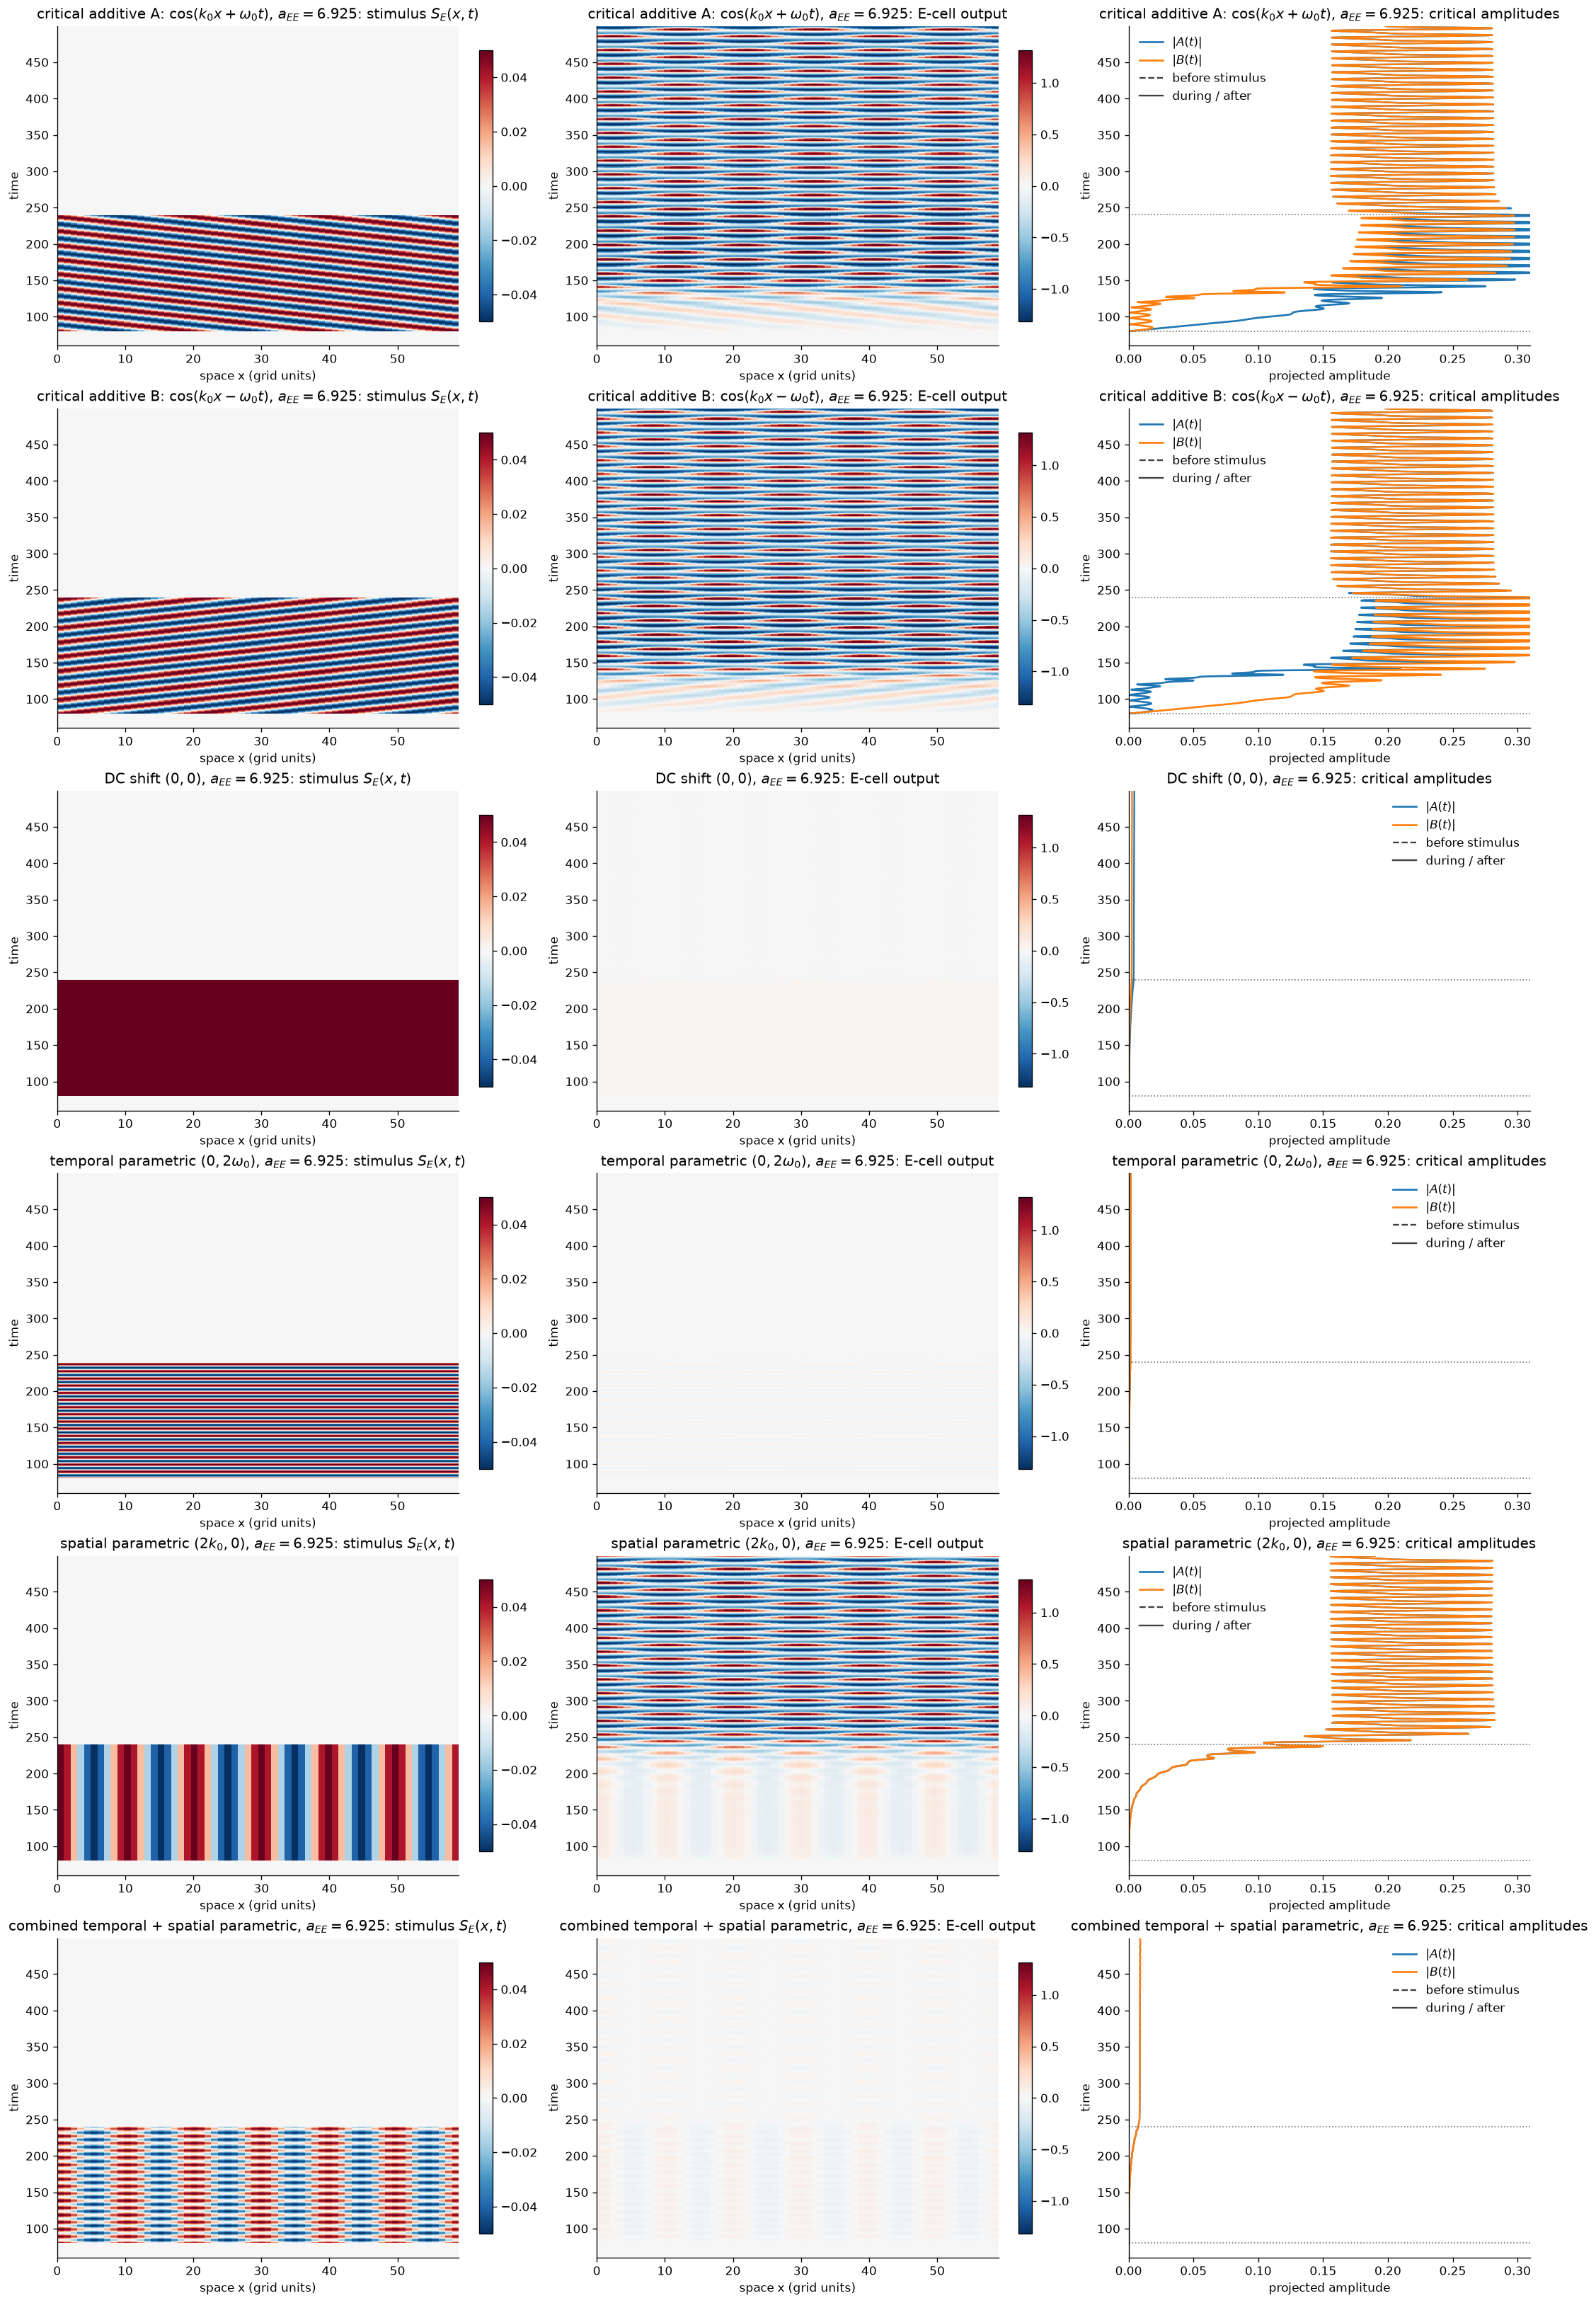

In [8]:
weak_amp = 0.05  # epsilon^2-scale total forcing amplitude
weak_window = dict(on=80.0, off=240.0)
resonant_cases = {
    r"critical additive A: $\cos(k_0x+\omega_0t)$": dict(
        direct_amp=weak_amp, direct_mode=k0, direct_omega=-omega0, **weak_window),
    r"critical additive B: $\cos(k_0x-\omega_0t)$": dict(
        direct_amp=weak_amp, direct_mode=k0, direct_omega=omega0, **weak_window),
    r"DC shift $(0,0)$": dict(
        temporal_amp=weak_amp, temporal_omega=0.0, **weak_window),
    r"temporal parametric $(0,2\omega_0)$": dict(
        temporal_amp=weak_amp, temporal_omega=2.0 * omega0, **weak_window),
    r"spatial parametric $(2k_0,0)$": dict(
        spatial_amp=weak_amp, spatial_mode=2 * k0, **weak_window),
    r"combined temporal + spatial parametric": dict(
        temporal_amp=0.5 * weak_amp, temporal_omega=2.0 * omega0,
        spatial_amp=0.5 * weak_amp, spatial_mode=2 * k0, **weak_window),
}

resonant_results = [
    simulate_wc_1d(aee_below, stimulus, seed=4, initial_scale=0.002)
    for stimulus in resonant_cases.values()
]

def forced_column_limits(results, time_window=(60.0, BASE["total"]), percentile=99.0):
    """Return common (stimulus, E output, A/B amplitude) limits."""
    output_values, amplitude_values = [], []
    for result in results:
        mask = ((result["t"] >= time_window[0]) &
                (result["t"] <= time_window[1]))
        output_values.append(result["E"][mask].ravel())
        A, B = critical_amplitudes(result)
        amplitude_values.extend([np.abs(A[mask]), np.abs(B[mask])])
    return (
        weak_amp,  # every total stimulus is bounded by this value
        symmetric_limit(np.concatenate(output_values), percentile=percentile),
        max(float(np.percentile(np.concatenate(amplitude_values), percentile)), 1e-12),
    )

FORCED_COLUMN_LIMITS = forced_column_limits(resonant_results)
print("Common forced-plot limits (stimulus, E, A/B):", FORCED_COLUMN_LIMITS)

_ = plot_stimulus_and_output(
    resonant_results,
    [fr"{label}, $a_{{EE}}={aee_below:.3f}$" for label in resonant_cases],
    figsize=(18, 27), time_window=(60.0, BASE["total"]),
    contrast_percentile=99.0, column_limits=FORCED_COLUMN_LIMITS,
)

In [9]:
def spatial_response_std(result, start, stop):
    mask = (result["t"] >= start) & (result["t"] < stop)
    field = result["E"][mask]
    return (field - field.mean(axis=1, keepdims=True)).std()

def dominant_mode_in_window(result, start, stop):
    mask = (result["t"] >= start) & (result["t"] < stop)
    field = result["E"][mask]
    centered = field - field.mean(axis=1, keepdims=True)
    power = np.mean(np.abs(np.fft.rfft(centered, axis=1)) ** 2, axis=0)
    return 1 + np.argmax(power[1:])

def mean_critical_amplitudes(result, start, stop):
    mask = (result["t"] >= start) & (result["t"] < stop)
    A, B = critical_amplitudes(result)
    return np.mean(np.abs(A[mask])), np.mean(np.abs(B[mask]))

print("Resonant epsilon^2-scale response below bifurcation:")
for label, result in zip(resonant_cases, resonant_results):
    during_std = spatial_response_std(result, 150.0, 240.0)
    during_mode = dominant_mode_in_window(result, 150.0, 240.0)
    mean_A, mean_B = mean_critical_amplitudes(result, 150.0, 240.0)
    late_std, _ = post_stimulus_summary(result, start=350.0)
    print(f"{label:>42s}: during std={during_std:.6f}, "
          f"mode={during_mode}, mean|A|={mean_A:.6f}, mean|B|={mean_B:.6f}")

Resonant epsilon^2-scale response below bifurcation:
critical additive A: $\cos(k_0x+\omega_0t)$: during std=0.519584, mode=3, mean|A|=0.248647, mean|B|=0.224844
critical additive B: $\cos(k_0x-\omega_0t)$: during std=0.519556, mode=3, mean|A|=0.224810, mean|B|=0.248625
                          DC shift $(0,0)$: during std=0.003542, mode=3, mean|A|=0.001979, mean|B|=0.001203
       temporal parametric $(0,2\omega_0)$: during std=0.001656, mode=3, mean|A|=0.000794, mean|B|=0.000768
             spatial parametric $(2k_0,0)$: during std=0.137962, mode=3, mean|A|=0.032689, mean|B|=0.032690
    combined temporal + spatial parametric: during std=0.043241, mode=6, mean|A|=0.002707, mean|B|=0.002733


### 3c. Representative nonresonant forcings

There are infinitely many nonresonant frequency–wavenumber choices, so this section uses a representative set at the same weak amplitude and below-onset parameter as the resonant section:

- a traveling input with both spatial and temporal detuning, $(2k_0,1.5\omega_0)$;
- a spatially uniform temporal input at $1.5\omega_0$ rather than $2\omega_0$;
- a static spatial input at $3k_0$ rather than $2k_0$;
- the two detuned separated inputs added together.

These rows use the exact stimulus, E-output, and A/B limits computed for the resonant figure, making the two experiment groups directly comparable. The $A/B$ column reports only the critical $k_0$ Hopf content; a visible stimulus at another spatial mode need not produce a large $A$ or $B$.

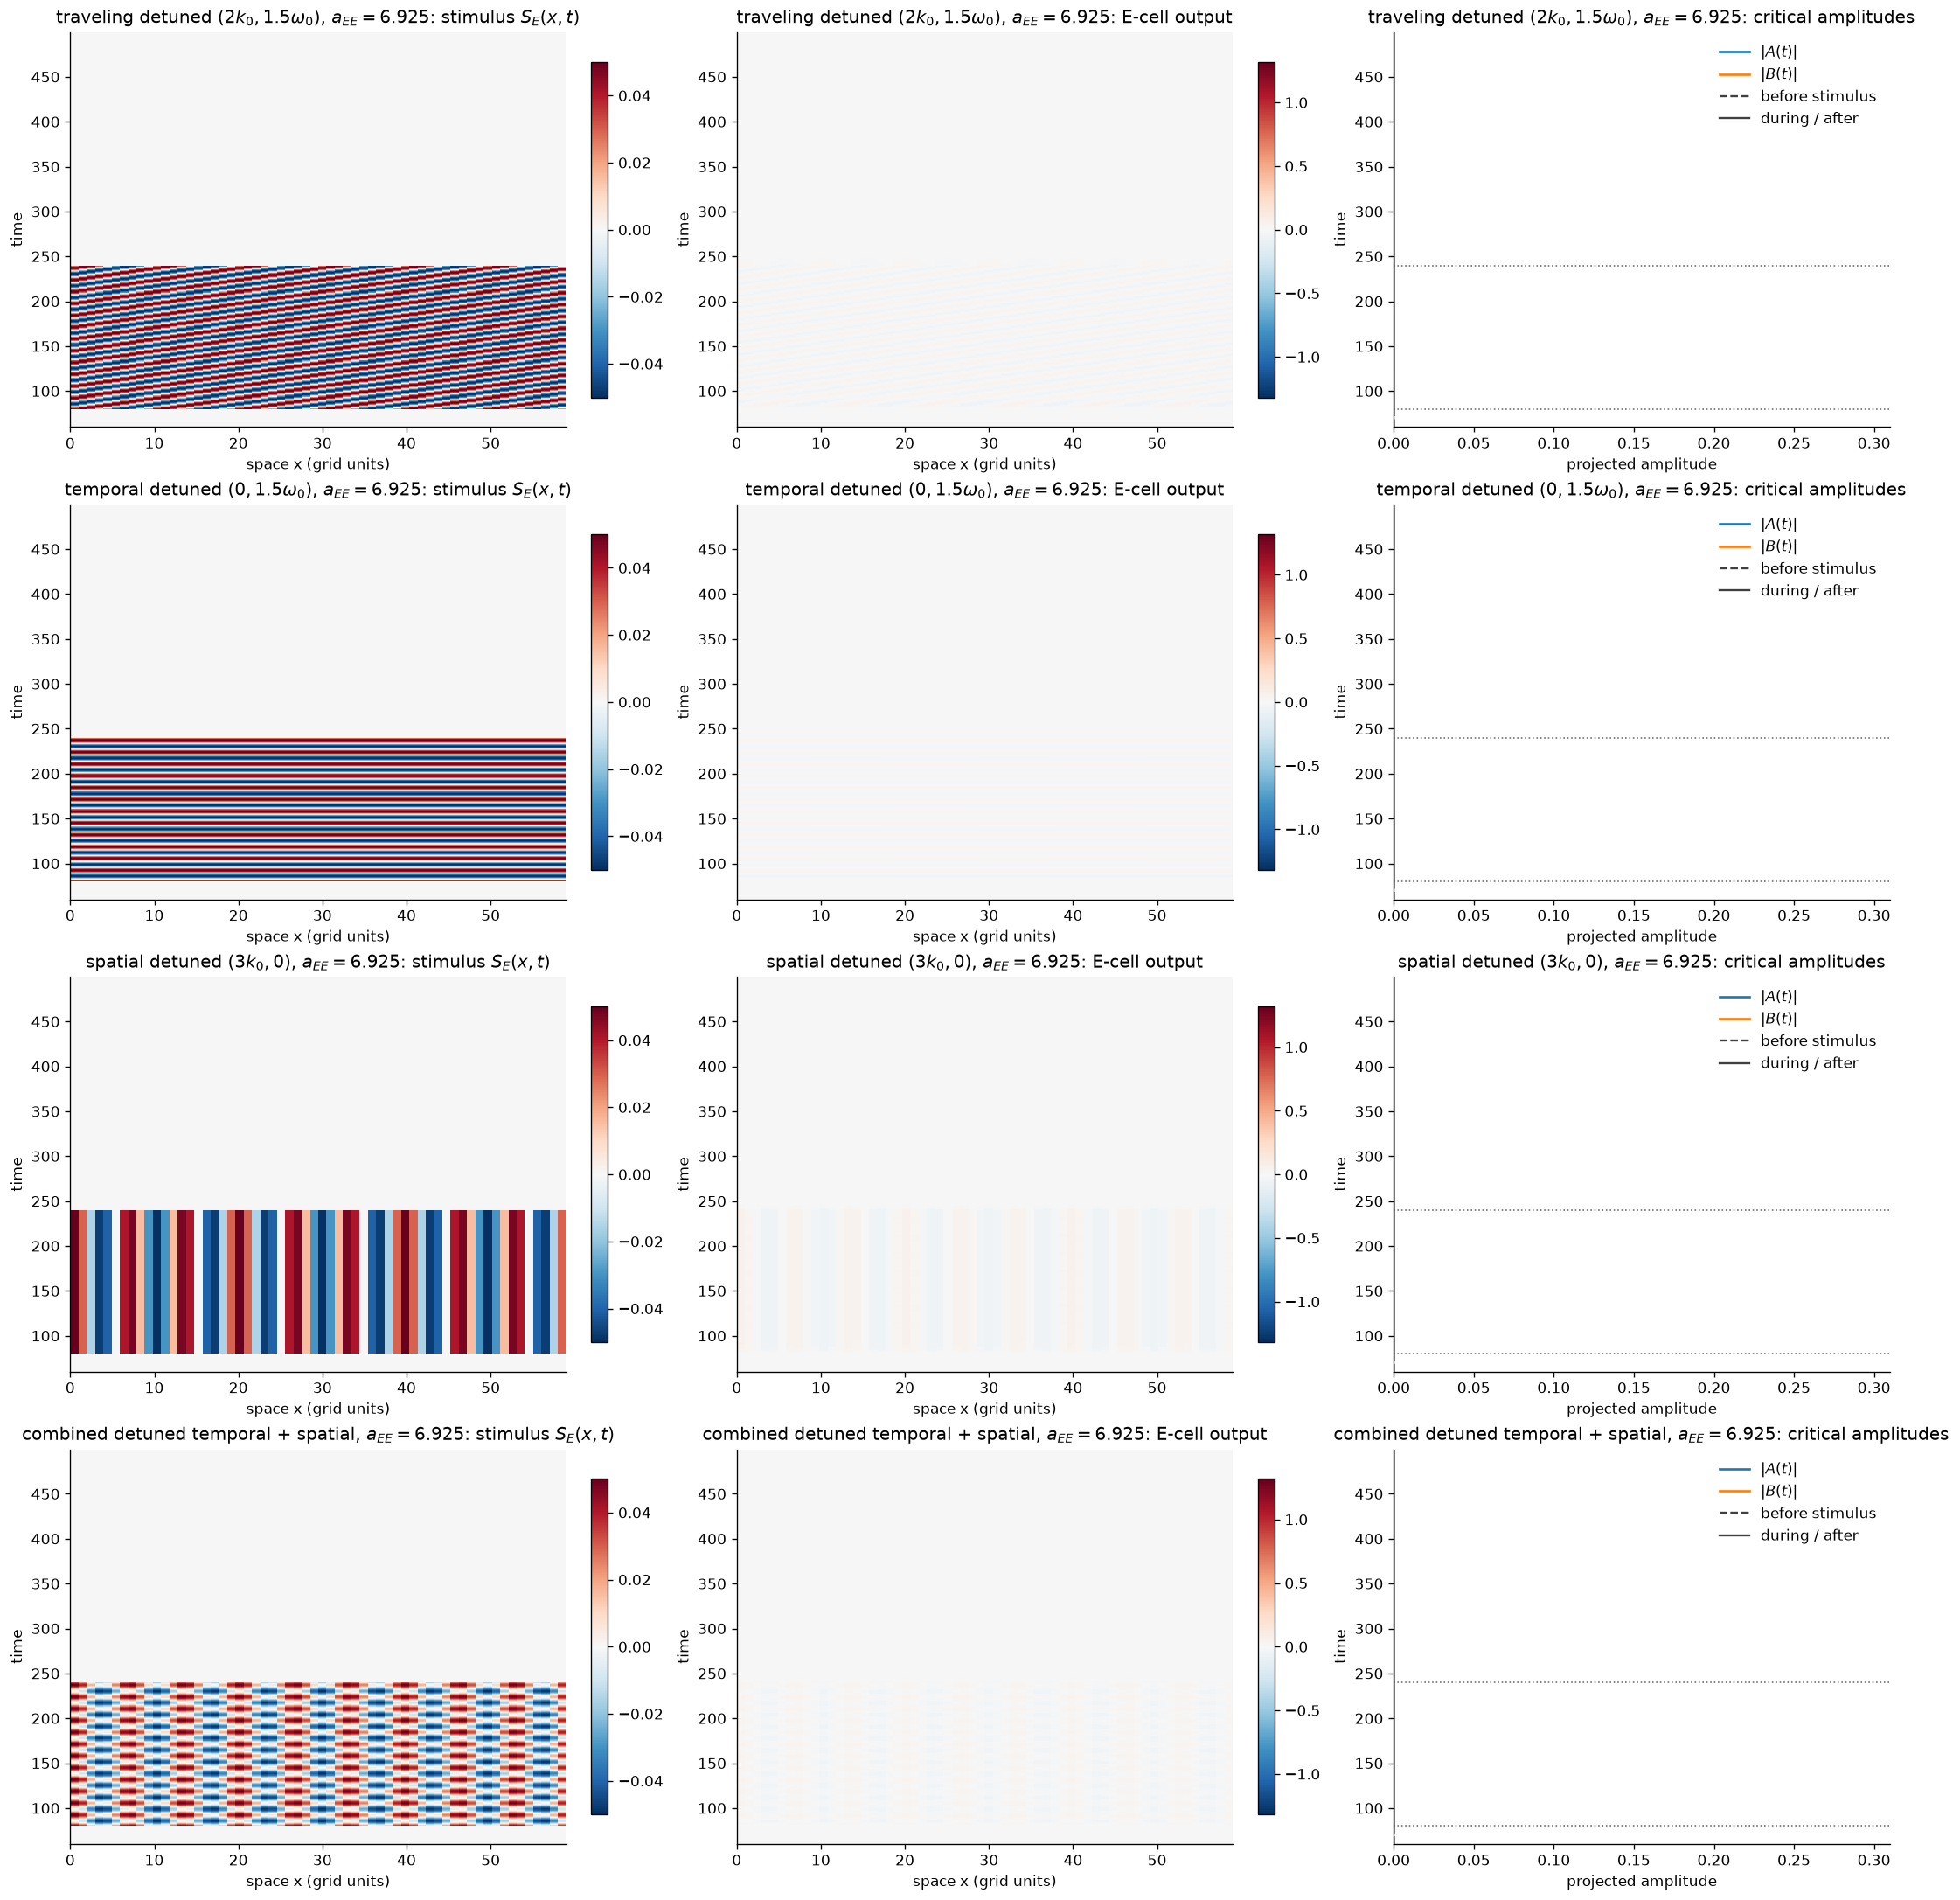

Nonresonant epsilon^2-scale response below bifurcation:
    traveling detuned $(2k_0,1.5\omega_0)$: during std=0.023983, mode=6, mean|A|=0.000255, mean|B|=0.000162
        temporal detuned $(0,1.5\omega_0)$: during std=0.000414, mode=3, mean|A|=0.000246, mean|B|=0.000157
                spatial detuned $(3k_0,0)$: during std=0.038562, mode=9, mean|A|=0.000251, mean|B|=0.000146
       combined detuned temporal + spatial: during std=0.019287, mode=9, mean|A|=0.000245, mean|B|=0.000150


In [10]:
nonresonant_cases = {
    r"traveling detuned $(2k_0,1.5\omega_0)$": dict(
        direct_amp=weak_amp, direct_mode=2 * k0, direct_omega=1.5 * omega0, **weak_window),
    r"temporal detuned $(0,1.5\omega_0)$": dict(
        temporal_amp=weak_amp, temporal_omega=1.5 * omega0, **weak_window),
    r"spatial detuned $(3k_0,0)$": dict(
        spatial_amp=weak_amp, spatial_mode=3 * k0, **weak_window),
    r"combined detuned temporal + spatial": dict(
        temporal_amp=0.5 * weak_amp, temporal_omega=1.5 * omega0,
        spatial_amp=0.5 * weak_amp, spatial_mode=3 * k0, **weak_window),
}

nonresonant_results = [
    simulate_wc_1d(aee_below, stimulus, seed=4, initial_scale=0.002)
    for stimulus in nonresonant_cases.values()
]
_ = plot_stimulus_and_output(
    nonresonant_results,
    [fr"{label}, $a_{{EE}}={aee_below:.3f}$" for label in nonresonant_cases],
    figsize=(18, 18), time_window=(60.0, BASE["total"]),
    contrast_percentile=99.0, column_limits=FORCED_COLUMN_LIMITS,
)

print("Nonresonant epsilon^2-scale response below bifurcation:")
for label, result in zip(nonresonant_cases, nonresonant_results):
    during_std = spatial_response_std(result, 150.0, 240.0)
    during_mode = dominant_mode_in_window(result, 150.0, 240.0)
    mean_A, mean_B = mean_critical_amplitudes(result, 150.0, 240.0)
    late_std, _ = post_stimulus_summary(result, start=350.0)
    print(f"{label:>42s}: during std={during_std:.6f}, "
          f"mode={during_mode}, mean|A|={mean_A:.6f}, mean|B|={mean_B:.6f}")

## Interpretation and useful changes

- The bifurcation scan predicts the first unstable pair $(\omega_0,\pm k_0)$ and connects directly to the two amplitudes $A$ and $B$ in the notes.
- At $a_{EE}=a_{EE}^*-0.1$, the $\epsilon^2$-scale forcing amplitude `0.05` makes direct and parametric resonant responses visible while retaining a below-onset operating point.
- Equal-amplitude spatially or temporally detuned probes produce much smaller responses. This is critical-mode selectivity, not spontaneous pattern formation.
- The below-onset response relaxes after switch-off, while the unforced above-onset field develops a spontaneous pattern.
- The separated temporal and spatial 2:1 inputs implement the leading parametric forcing case from the notes at the same weak scale.
- The third plot column separates the critical field into the two counter-propagating amplitudes $A$ and $B$; dominance of one magnitude indicates a traveling-wave bias, while comparable magnitudes indicate a standing/mixed wave.

To explore other stimuli, edit `resonant_cases` or `nonresonant_cases`. Set `rie` in `BASE` to stimulate I cells as a fixed fraction of E-cell input, change `spatial_mode`, or change `temporal_omega`. To reproduce a y-varying 2D spatial field or video, use the full `simulate_wc2d` function in `wc2dn.txt`; the present reduction is deliberately chosen for the requested x-versus-time plot.